In [46]:
%pip install kagglehub torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118 opencv-python


Looking in indexes: https://download.pytorch.org/whl/cu118


In [47]:
import kagglehub
import shutil
from pathlib import Path

# Download or reuse the existing dataset
dataset_path = kagglehub.dataset_download(
    "ashfakyeafi/road-vehicle-images-dataset"
)

# Choose a writable destination in Colab
destination = Path("/content/road-vehicle-images-dataset")

# Copy the dataset if it is not already there
if not destination.exists():
    shutil.copytree(dataset_path, destination)

# Use this path for all your operations
dataset_path = destination

print("Dataset path:", dataset_path)
print("Dataset exists:", dataset_path.exists())
print("Contents:", list(dataset_path.iterdir()))

Using Colab cache for faster access to the 'road-vehicle-images-dataset' dataset.
Dataset path: /content/road-vehicle-images-dataset
Dataset exists: True
Contents: [PosixPath('/content/road-vehicle-images-dataset/trafic_data')]


In [48]:
import pathlib

absentFiles = []
corruptedFiles=[]

for split in ["train", "valid"]:
    images_path = pathlib.Path(dataset_path) / "trafic_data" / split / "images"
    labels_path = pathlib.Path(dataset_path) / "trafic_data" / split / "labels"

    for f in images_path.iterdir():
      label_file = labels_path / f"{f.stem}.txt"
      if not label_file.is_file():
            absentFiles.append(f"{split}/{f.name}")

    for folder in ["images", "labels"]:
        path = pathlib.Path(dataset_path) / "trafic_data" / split / folder

        folder_files = [f for f in path.iterdir() if f.is_file()]
        print(f"{split}/{folder}: {len(folder_files)} files")

        for f in path.iterdir():
          if not f.is_file() or f.suffix not in (['.jpg'] if folder == 'images' else ['.txt']):
              corruptedFiles.append(str(f))
          elif folder == 'labels' and not f.read_text().strip():
              corruptedFiles.append(str(f))

print("\nImages without corresponding labels:")
print(absentFiles)
print("\nCorrupted files:")
print(corruptedFiles)

train/images: 1622 files
train/labels: 1622 files
valid/images: 300 files
valid/labels: 300 files

Images without corresponding labels:
[]

Corrupted files:
[]


In [49]:
for corruptFile in corruptedFiles:
  path = pathlib.Path(corruptFile)
  # print(path)
  imagePath = pathlib.Path(dataset_path) / "trafic_data" / "train" / "images" / f"{path.stem}.jpg"
  imagePath.unlink()
  path.unlink()

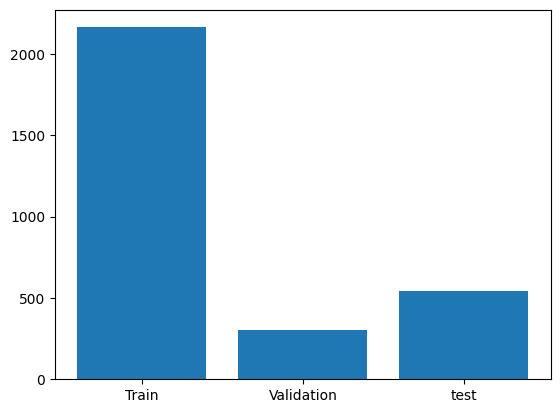

In [50]:
import matplotlib.pyplot as plt
import pandas as pd
pd = pd.DataFrame({
    'Dataset': ['Train', 'Validation','test'],
    'Number of images': [2164, 300,540]
})
plt.bar(pd['Dataset'],pd['Number of images'])
plt.show()

In [51]:
globalPath = pathlib.Path('/content/road-vehicle-images-dataset/trafic_data/test')
globalPath.mkdir(parents=True, exist_ok=True)



In [ ]:
testPathImages = pathlib.Path('/content/road-vehicle-images-dataset/trafic_data/test/images')
testPathImages.mkdir(parents=True, exist_ok=True)

testPathLables = pathlib.Path('/content/road-vehicle-images-dataset/trafic_data/test/labels')
testPathLables.mkdir(parents=True, exist_ok=True)

In [ ]:
import random

directoryImages = pathlib.Path("/content/road-vehicle-images-dataset/trafic_data/train/images")
directoryLabels = pathlib.Path("/content/road-vehicle-images-dataset/trafic_data/train/labels")

random.seed(42)

files = list(directoryImages.glob("*.jpg"))
selected_files = random.sample(files, 540)

for newTestFile in selected_files:
    destinationFileImages = testPathImages / newTestFile.name
    sourceFileImages = newTestFile
    sourceFileImages.rename(destinationFileImages)

    destinationFileLabels = testPathLables / f"{newTestFile.stem}.txt"
    sourceFileLabels = directoryLabels / f"{newTestFile.stem}.txt"
    sourceFileLabels.rename(destinationFileLabels)

In [ ]:
print(dataset_path)
otherjpg=[]
for split in ['train','valid','test']:
  path = pathlib.Path(dataset_path) / "trafic_data" / split / "images"
  for image in path.iterdir():
    if image.suffix not in ['.jpg']:
        otherjpg.append(image)

print(otherjpg)

/content/road-vehicle-images-dataset
[]


In [ ]:
!apt-get install git

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
git is already the newest version (1:2.43.0-1ubuntu7.4).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:

!git clone https://github.com/WongKinYiu/yolov9

fatal: destination path 'yolov9' already exists and is not an empty directory.


In [ ]:
cd /content/road-vehicle-images-dataset/trafic_data/yolov9

/content/road-vehicle-images-dataset/trafic_data/yolov9


In [ ]:
pip install -r requirements.txt

In [ ]:
# path = pathlib.Path('/content/yolov9')
# yolopath = path.rglob('data/hyps/hyp.scratch-high.yaml')
# print(list(yolopath))

In [ ]:
from pathlib import Path

repo_path = Path("/content/road-vehicle-images-dataset/trafic_data")

# Find pretrained weights (.pt)
for file in repo_path.rglob("*.pt"):
    print(file)

# Find YOLOv9 model configurations (.yaml)
for file in (repo_path / "yolov9" / "models" / "detect").glob("yolov9-c.yaml"):
    print(file)

/content/road-vehicle-images-dataset/trafic_data/yolov9-c.pt
/content/road-vehicle-images-dataset/trafic_data/yolov9/models/detect/yolov9-c.yaml


In [ ]:
from pathlib import Path

repo_path = Path("/content/road-vehicle-images-dataset/trafic_data")

weights_path = repo_path / "yolov9-c.pt"
config_path = repo_path / "yolov9" / "models/detect/yolov9-c.yaml"
hyp_path = repo_path / "yolov9" / "data/hyps/hyp.scratch-high.yaml"

print("Poids disponibles :", weights_path.exists())
print("Configuration disponible :", config_path.exists())
print("Hyperparamètres disponibles :", hyp_path.exists())

Poids disponibles : True
Configuration disponible : True
Hyperparamètres disponibles : True


In [ ]:
import torch

# Only use this for a trusted YOLOv9 checkpoint.
_original_torch_load = torch.load

def torch_load_compat(*args, **kwargs):
    kwargs.setdefault("weights_only", False)
    return _original_torch_load(*args, **kwargs)

torch.load = torch_load_compat

print("YOLOv9 checkpoint-loading compatibility fix applied.")

YOLOv9 checkpoint-loading compatibility fix applied.


In [ ]:
from pathlib import Path
import torch
import detect_dual

repo_path = Path("/content/road-vehicle-images-dataset/trafic_data")

weights_path = repo_path / "yolov9-c.pt"

image_path = repo_path / "train/images/05_jpg.rf.11a2e7ce391a1e74960099f7923f27f5.jpg"


device = "0" if torch.cuda.is_available() else "cpu"

# Run inference using Python
detect_dual.run(
    weights=str(weights_path),
    source=str(image_path),
    imgsz=(640, 640),
    conf_thres=0.25,
    device=device,
    project=str(repo_path / "runs/detect"),
    name="yolov9c_pretrained",
    exist_ok=True
)

YOLO 🚀 v0.1-104-g5b1ea9a Python-3.13.18 torch-2.11.0+cpu CPU

Fusing layers... 
Model summary: 604 layers, 50880768 parameters, 0 gradients, 237.6 GFLOPs
image 1/1 /content/road-vehicle-images-dataset/trafic_data/train/images/05_jpg.rf.11a2e7ce391a1e74960099f7923f27f5.jpg: 448x640 14 persons, 1 bicycle, 11 cars, 1 motorcycle, 1 truck, 2482.6ms
Speed: 4.9ms pre-process, 2482.6ms inference, 2.0ms NMS per image at shape (1, 3, 640, 640)
Results saved to /content/road-vehicle-images-dataset/trafic_data/runs/detect/yolov9c_pretrained


In [ ]:
from pathlib import Path
import train_dual

repo_path = Path("/content/road-vehicle-images-dataset/trafic_data/yolov9")

train_dual.run(
    data=str(repo_path / "data.yaml"),
    weights=str(repo_path / "yolov9-c.pt"),
    imgsz=640,
    batch_size=16,
    epochs=50,
    device="0"
)